# Task 10: Product Price vs. Units Sold – Polynomial Regression & Product Segmentation

**Objective:**
- Implement polynomial regression (degrees 1–5) with cross-validation
- Test multiple feature transformations (log, sqrt, Box-Cox)
- Visualize product price and sales trends
- Segment products by price band and sales tier

**Input:** `data/processed/womens_clothing_scaled.csv`

## 1. Setup & Imports

In [15]:
import os
import logging
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
from scipy.stats import boxcox
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score, KFold
from sklearn.metrics import r2_score, mean_squared_error

warnings.filterwarnings('ignore')

# ── Logging ────────────────────────────────────────────────────────────────────
os.makedirs('../../logs', exist_ok=True)
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s | %(levelname)s | %(message)s',
    handlers=[
        logging.FileHandler('../../logs/task_10.log', mode='w'),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger('Task10')
logger.info('Task 10 started.')

# ── Dark theme style ───────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': '#0f0f1a', 'axes.facecolor': '#1a1a2e',
    'axes.edgecolor': '#444466',   'axes.labelcolor': '#e0e0ff',
    'xtick.color': '#c0c0e0',      'ytick.color': '#c0c0e0',
    'text.color': '#e0e0ff',       'grid.color': '#2a2a4a',
    'grid.linestyle': '--',        'font.family': 'DejaVu Sans',
    'font.size': 11,               'axes.titlesize': 13,
    'axes.titleweight': 'bold',    'legend.facecolor': '#1a1a2e',
    'legend.edgecolor': '#444466',
})
PALETTE = ['#7c5cbf', '#e96479', '#f5a623', '#4fc3f7', '#81c784', '#ff8a65']
os.makedirs('../../reports', exist_ok=True)
print('✅ Setup complete.')

2026-11-19 15:23:26,214 | INFO | Task 10 started.


✅ Setup complete.


## 2. Load Data & Identify Columns

In [16]:
df = pd.read_csv('../data/processed/womens_clothing_scaled.csv')
logger.info(f'Dataset: {df.shape[0]} rows × {df.shape[1]} cols')
print(f'Shape: {df.shape}')
print(df.dtypes)
df.head()

2026-11-19 15:23:26,359 | INFO | Dataset: 1539 rows × 40 cols


Shape: (1539, 40)
title                               str
title_orig                          str
price                           float64
retail_price                    float64
currency_buyer                      str
units_sold                        int64
uses_ad_boosts                     bool
rating                          float64
rating_count                    float64
rating_five_count               float64
rating_four_count               float64
rating_three_count              float64
rating_two_count                float64
rating_one_count                float64
badges_count                      int64
badge_local_product                bool
badge_product_quality              bool
badge_fast_shipping                bool
tags                                str
product_color                       str
product_variation_size_id           str
product_variation_inventory     float64
shipping_option_name                str
shipping_option_price           float64
shipping_is_express   

,title,title_orig,price,retail_price,currency_buyer,units_sold,uses_ad_boosts,rating,rating_count,rating_five_count,...,merchant_name,merchant_info_subtitle,merchant_rating_count,merchant_rating,merchant_id,merchant_has_profile_picture,merchant_profile_picture,product_url,product_picture,product_id
0,2020 Summer Vintage Flamingo Print Pajamas Se...,2020 Summer Vintage Flamingo Print Pajamas Se...,1.545894,0.210526,EUR,100,False,-0.160714,-0.126328,-0.149871,...,zgrdejia,(568 notes),-0.338893,0.344750,595097d6a26f6e070cb878d1,False,NaN,https://www.wish.com/c/5e9ae51d43d6a96e303acdb0,https://contestimg.wish.com/api/webimage/5e9ae...,5e9ae51d43d6a96e303acdb0
1,SSHOUSE Summer Casual Sleeveless Soirée Party ...,Women's Casual Summer Sleeveless Sexy Mini Dress,0.000000,0.631579,EUR,12350,True,-0.714286,2.340614,2.516796,...,sarahouse,"83 % avis positifs (17,752 notes)",0.424450,-0.601793,56458aa03a698c35c9050988,False,NaN,https://www.wish.com/c/58940d436a0d3d5da4e95a38,https://contestimg.wish.com/api/webimage/58940...,58940d436a0d3d5da4e95a38
2,2020 Nouvelle Arrivée Femmes Printemps et Été ...,2020 New Arrival Women Spring and Summer Beach...,0.000000,1.736842,EUR,100,False,-0.500000,-0.173554,-0.204134,...,hxt520,86 % avis positifs (295 notes),-0.351021,-0.228892,5d464a1ffdf7bc44ee933c65,False,NaN,https://www.wish.com/c/5ea10e2c617580260d55310a,https://contestimg.wish.com/api/webimage/5ea10...,5ea10e2c617580260d55310a
3,Hot Summer Cool T-shirt pour les femmes Mode T...,Hot Summer Cool T Shirt for Women Fashion Tops...,0.000000,-0.105263,EUR,5000,True,0.321429,0.493506,0.545220,...,allenfan,"(23,832 notes)",0.694534,-0.102309,58cfdefdacb37b556efdff7c,False,NaN,https://www.wish.com/c/5cedf17ad1d44c52c59e4aca,https://contestimg.wish.com/api/webimage/5cedf...,5cedf17ad1d44c52c59e4aca
4,Femmes Shorts d'été à lacets taille élastique ...,Women Summer Shorts Lace Up Elastic Waistband ...,-1.020290,-0.368421,EUR,100,True,-1.339286,-0.166470,-0.201550,...,happyhorses,"85 % avis positifs (14,482 notes)",0.279191,-0.180261,5ab3b592c3911a095ad5dadb,False,NaN,https://www.wish.com/c/5ebf5819ebac372b070b0e70,https://contestimg.wish.com/api/webimage/5ebf5...,5ebf5819ebac372b070b0e70


In [17]:
# Use columns that exist in the product dataset; do not silently substitute fields.
FEATURE_COL = 'price'
TARGET_COL = 'units_sold'
CATEGORY_COL = 'product_color'

required_cols = [FEATURE_COL, TARGET_COL]
missing_cols = [col for col in required_cols if col not in df.columns]
if missing_cols:
    raise KeyError(f'Required product-analysis columns are missing: {missing_cols}')

print(f'Feature column : {FEATURE_COL}')
print(f'Target column  : {TARGET_COL}')
print(f'Category column: {CATEGORY_COL if CATEGORY_COL in df.columns else "not available"}')
logger.info(f'Feature: {FEATURE_COL}, Target: {TARGET_COL}, Category: {CATEGORY_COL}')

2026-11-19 15:23:26,527 | INFO | Feature: price, Target: units_sold, Category: product_color


Feature column : price
Target column  : units_sold
Category column: product_color


In [18]:
# ── Prepare clean working dataframe ────────────────────────────────────────────
work_cols = [FEATURE_COL, TARGET_COL]
if CATEGORY_COL in df.columns:
    work_cols.append(CATEGORY_COL)
wdf = df[work_cols].dropna(subset=[FEATURE_COL, TARGET_COL]).copy()
print(f'Working rows after dropna: {len(wdf)}')

X_raw = wdf[[FEATURE_COL]].to_numpy(dtype=float)
y_raw = wdf[TARGET_COL].to_numpy(dtype=float)
if X_raw.shape[0] != y_raw.shape[0]:
    raise ValueError(f'Feature/target row mismatch: {X_raw.shape[0]} != {y_raw.shape[0]}')

Working rows after dropna: 1539


## 3. Raw Scatter – Price vs. Units Sold

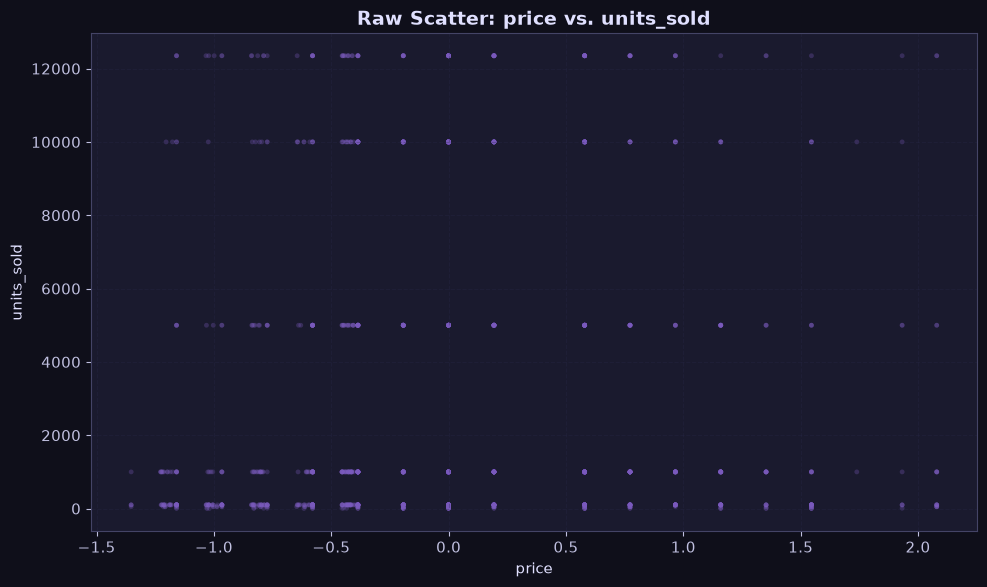

2026-11-19 15:23:27,378 | INFO | Raw scatter saved.


In [19]:
fig, ax = plt.subplots(figsize=(10, 6))
fig.patch.set_facecolor('#0f0f1a')
ax.scatter(X_raw.ravel(), y_raw, alpha=0.3, s=12, color='#7c5cbf', edgecolors='none')
ax.set_xlabel(FEATURE_COL); ax.set_ylabel(TARGET_COL)
ax.set_title(f'Raw Scatter: {FEATURE_COL} vs. {TARGET_COL}', fontsize=14)
ax.yaxis.grid(True, alpha=0.3); ax.xaxis.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../../reports/task_10_raw_scatter.png', dpi=150, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
logger.info('Raw scatter saved.')

## 4. Polynomial Regression – Price vs. Units Sold (Degrees 1 to 5)

In [20]:
X_raw = wdf[[FEATURE_COL]].to_numpy(dtype=float)
y_raw = wdf[TARGET_COL].to_numpy(dtype=float)
if X_raw.shape[0] != y_raw.shape[0]:
    raise ValueError(f'Feature/target row mismatch: {X_raw.shape[0]} != {y_raw.shape[0]}')

kf = KFold(n_splits=5, shuffle=True, random_state=42)
degrees = range(1, 6)
poly_results = []

for deg in degrees:
    pipe = Pipeline([
        ('poly',  PolynomialFeatures(degree=deg, include_bias=False)),
        ('scale', StandardScaler()),
        ('ridge', Ridge(alpha=1.0))
    ])
    cv_r2   = cross_val_score(pipe, X_raw, y_raw, cv=kf, scoring='r2')
    cv_rmse = np.sqrt(-cross_val_score(pipe, X_raw, y_raw, cv=kf,
                                        scoring='neg_mean_squared_error'))
    pipe.fit(X_raw, y_raw)
    y_pred = pipe.predict(X_raw)
    train_r2 = r2_score(y_raw, y_pred)

    res = {
        'Degree': deg,
        'CV_R2_Mean':   round(cv_r2.mean(), 4),
        'CV_R2_Std':    round(cv_r2.std(),  4),
        'CV_RMSE_Mean': round(cv_rmse.mean(), 4),
        'CV_RMSE_Std':  round(cv_rmse.std(),  4),
        'Train_R2':     round(train_r2, 4),
        'Pipeline':     pipe
    }
    poly_results.append(res)
    print(f'Degree {deg}: CV R²={cv_r2.mean():.4f} ± {cv_r2.std():.4f}  '
          f'CV RMSE={cv_rmse.mean():.4f} ± {cv_rmse.std():.4f}')
    logger.info(f'Degree {deg}: CV_R2={cv_r2.mean():.4f}')

best_idx = np.argmax([r['CV_R2_Mean'] for r in poly_results])
best_deg = poly_results[best_idx]['Degree']
best_pipe = poly_results[best_idx]['Pipeline']
print(f'\n✅ Best degree by CV R²: {best_deg}')

2026-11-19 15:23:27,655 | INFO | Degree 1: CV_R2=-0.0080
2026-11-19 15:23:27,789 | INFO | Degree 2: CV_R2=0.0083


Degree 1: CV R²=-0.0080 ± 0.0078  CV RMSE=4216.5459 ± 186.1789
Degree 2: CV R²=0.0083 ± 0.0138  CV RMSE=4182.4324 ± 187.5138


2026-11-19 15:23:27,898 | INFO | Degree 3: CV_R2=0.0122
2026-11-19 15:23:28,025 | INFO | Degree 4: CV_R2=0.0116


Degree 3: CV R²=0.0122 ± 0.0121  CV RMSE=4174.4426 ± 192.7706
Degree 4: CV R²=0.0116 ± 0.0141  CV RMSE=4175.7202 ± 192.4084


2026-11-19 15:23:28,163 | INFO | Degree 5: CV_R2=0.0105


Degree 5: CV R²=0.0105 ± 0.0142  CV RMSE=4178.1150 ± 193.7057

✅ Best degree by CV R²: 3


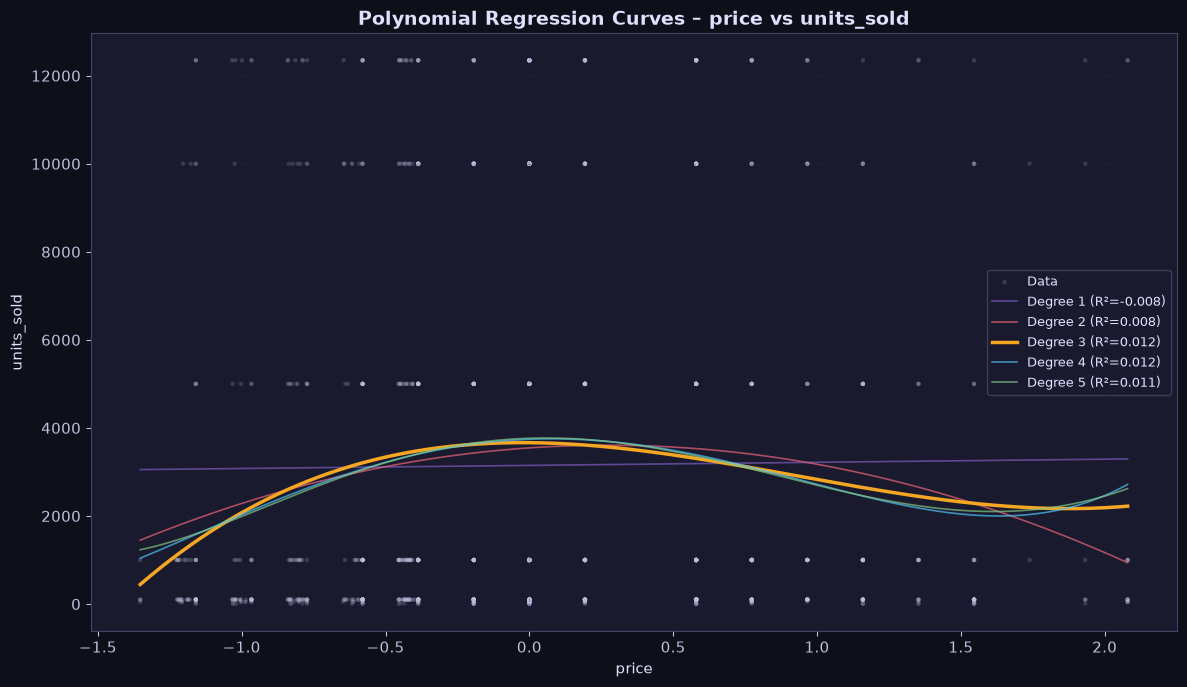

2026-11-19 15:23:30,124 | INFO | Polynomial curves plot saved.


In [21]:
# ── Overlay all regression curves on scatter ───────────────────────────────────
X_smooth = np.linspace(X_raw.min(), X_raw.max(), 300).reshape(-1, 1)

fig, ax = plt.subplots(figsize=(12, 7))
fig.patch.set_facecolor('#0f0f1a')
ax.scatter(X_raw.ravel(), y_raw, alpha=0.2, s=10, color='#c0c0e0', edgecolors='none', label='Data')

for r in poly_results:
    y_smooth = r['Pipeline'].predict(X_smooth)
    lw = 2.5 if r['Degree'] == best_deg else 1.2
    alpha = 1.0 if r['Degree'] == best_deg else 0.7
    label = f'Degree {r["Degree"]} (R²={r["CV_R2_Mean"]:.3f})'
    ax.plot(X_smooth.ravel(), y_smooth, color=PALETTE[(r['Degree']-1) % len(PALETTE)],
            linewidth=lw, alpha=alpha, label=label)

ax.set_xlabel(FEATURE_COL); ax.set_ylabel(TARGET_COL)
ax.set_title(f'Polynomial Regression Curves – {FEATURE_COL} vs {TARGET_COL}', fontsize=14)
ax.legend(fontsize=9); ax.yaxis.grid(True, alpha=0.3); ax.xaxis.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../../reports/task_10_polynomial_curves.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
logger.info('Polynomial curves plot saved.')

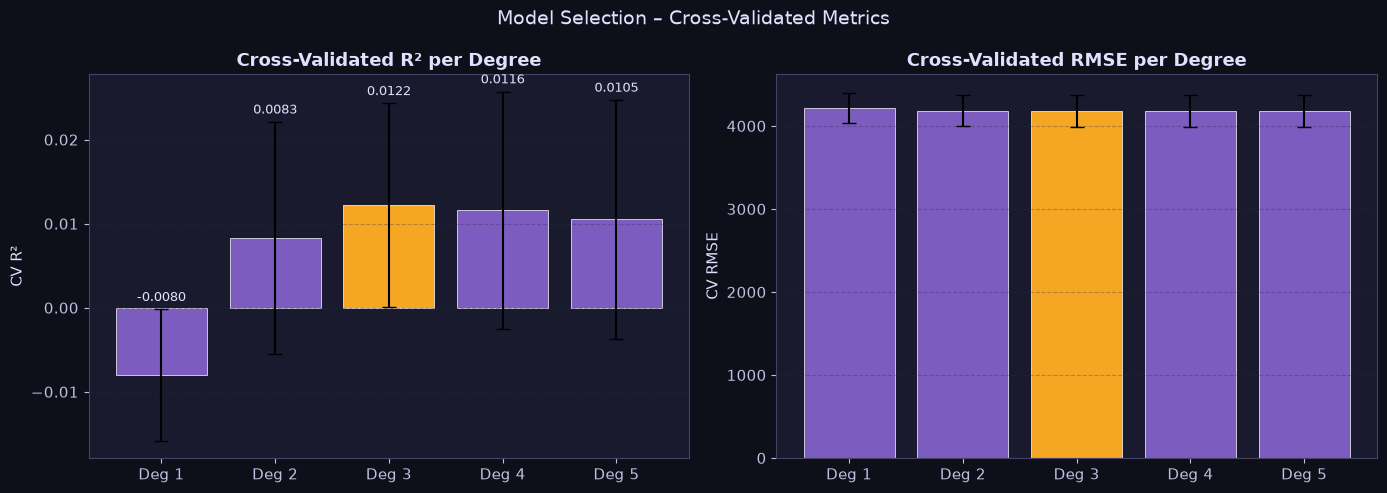

In [22]:
# ── CV R² and RMSE comparison bar charts ──────────────────────────────────────
summary_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'Pipeline'} for r in poly_results])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Model Selection – Cross-Validated Metrics', fontsize=14, color='#e0e0ff')

bar_colors = [('#f5a623' if d == best_deg else '#7c5cbf') for d in summary_df['Degree']]
axes[0].bar([f'Deg {d}' for d in summary_df['Degree']], summary_df['CV_R2_Mean'],
            yerr=summary_df['CV_R2_Std'], color=bar_colors,
            edgecolor='white', linewidth=0.5, capsize=5)
axes[0].set_title('Cross-Validated R² per Degree'); axes[0].set_ylabel('CV R²')
axes[0].yaxis.grid(True, alpha=0.3)
for i, (v, s) in enumerate(zip(summary_df['CV_R2_Mean'], summary_df['CV_R2_Std'])):
    axes[0].text(i, v + s + 0.001, f'{v:.4f}', ha='center', fontsize=9, color='#e0e0ff')

axes[1].bar([f'Deg {d}' for d in summary_df['Degree']], summary_df['CV_RMSE_Mean'],
            yerr=summary_df['CV_RMSE_Std'], color=bar_colors,
            edgecolor='white', linewidth=0.5, capsize=5)
axes[1].set_title('Cross-Validated RMSE per Degree'); axes[1].set_ylabel('CV RMSE')
axes[1].yaxis.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../../reports/task_10_cv_comparison.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

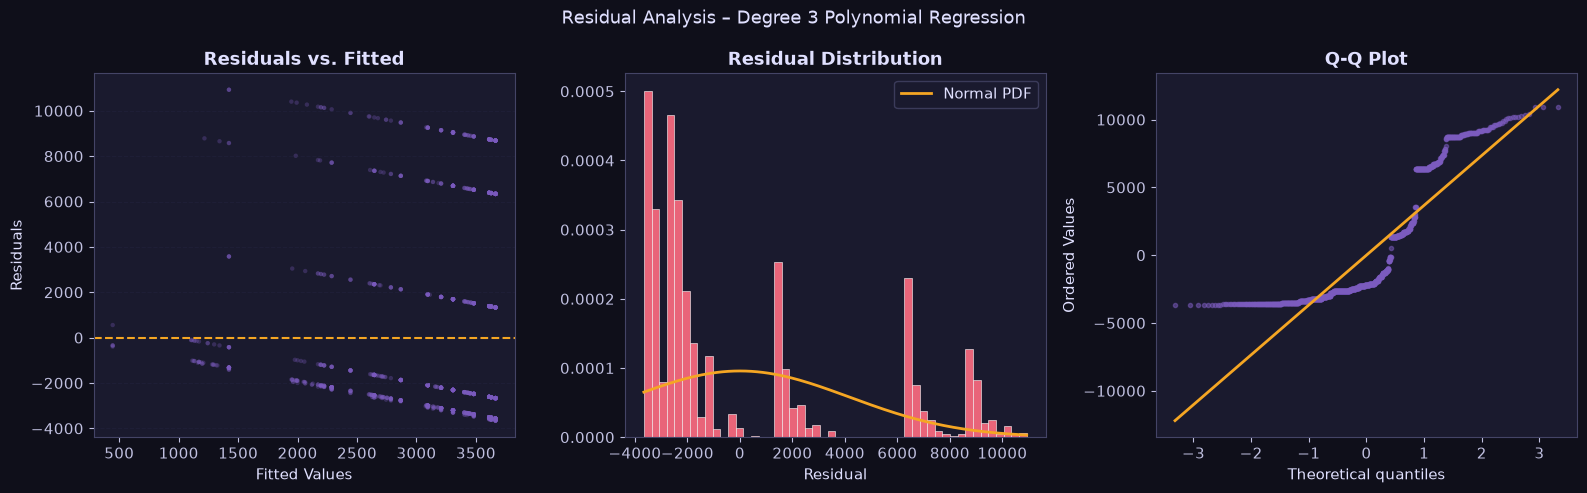

2026-11-19 15:23:34,126 | INFO | Residual plots saved.


In [23]:
# ── Residual plots for best model ─────────────────────────────────────────────
y_pred_best = best_pipe.predict(X_raw)
residuals = y_raw - y_pred_best

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle(f'Residual Analysis – Degree {best_deg} Polynomial Regression', fontsize=13, color='#e0e0ff')

axes[0].scatter(y_pred_best, residuals, alpha=0.3, s=10, color='#7c5cbf', edgecolors='none')
axes[0].axhline(0, color='#f5a623', linewidth=1.5, linestyle='--')
axes[0].set_xlabel('Fitted Values'); axes[0].set_ylabel('Residuals')
axes[0].set_title('Residuals vs. Fitted'); axes[0].yaxis.grid(True, alpha=0.3)

axes[1].hist(residuals, bins=50, color='#e96479', edgecolor='white', linewidth=0.4, density=True)
xr = np.linspace(residuals.min(), residuals.max(), 200)
axes[1].plot(xr, stats.norm.pdf(xr, residuals.mean(), residuals.std()),
             color='#f5a623', linewidth=2, label='Normal PDF')
axes[1].set_title('Residual Distribution'); axes[1].set_xlabel('Residual'); axes[1].legend()

stats.probplot(residuals, plot=axes[2])
axes[2].set_title('Q-Q Plot'); axes[2].get_lines()[0].set(color='#7c5cbf', markersize=3, alpha=0.5)
axes[2].get_lines()[1].set(color='#f5a623', linewidth=2)

plt.tight_layout()
plt.savefig('../../reports/task_10_residuals.png', dpi=150, bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
logger.info('Residual plots saved.')

## 5. Feature Transformation Testing

In [24]:
transform_results = []

def try_transform(name, y_t, X=X_raw):
    """Fit linear regression on a transformed target and return CV metrics."""
    pipe = Pipeline([('scale', StandardScaler()), ('lr', LinearRegression())])
    cv_r2 = cross_val_score(pipe, X, y_t, cv=kf, scoring='r2')
    transform_results.append({
        'Transform': name,
        'CV_R2_Mean': round(cv_r2.mean(), 4),
        'CV_R2_Std':  round(cv_r2.std(),  4)
    })
    print(f'{name:20s}: CV R²={cv_r2.mean():.4f} ± {cv_r2.std():.4f}')

# Raw target
try_transform('Linear (Raw)', y_raw)

# Log transform (shift if needed)
y_shift = y_raw - y_raw.min() + 1
try_transform('Log(y)',       np.log(y_shift))
try_transform('Sqrt(y)',      np.sqrt(y_shift))
try_transform('Square(y)',    y_shift ** 2)

# Box-Cox (requires positive values)
try:
    y_bc, lam = boxcox(y_shift)
    try_transform(f'Box-Cox(λ={lam:.2f})', y_bc)
except Exception as e:
    print(f'Box-Cox failed: {e}')

transform_df = pd.DataFrame(transform_results)
transform_df.to_csv('../../reports/task_10_transformation_comparison.csv', index=False)
print('\n✅ Transformations done.')
logger.info('Transformation tests complete.')
display(transform_df)

Linear (Raw)        : CV R²=-0.0080 ± 0.0078
Log(y)              : CV R²=-0.0054 ± 0.0067
Sqrt(y)             : CV R²=-0.0074 ± 0.0076
Square(y)           : CV R²=-0.0080 ± 0.0080
Box-Cox(λ=0.05)     : CV R²=-0.0056 ± 0.0069

✅ Transformations done.


2026-11-19 15:23:35,231 | INFO | Transformation tests complete.


,Transform,CV_R2_Mean,CV_R2_Std
0,Linear (Raw),-0.0080,0.0078
1,Log(y),-0.0054,0.0067
2,Sqrt(y),-0.0074,0.0076
3,Square(y),-0.0080,0.0080
4,Box-Cox(λ=0.05),-0.0056,0.0069


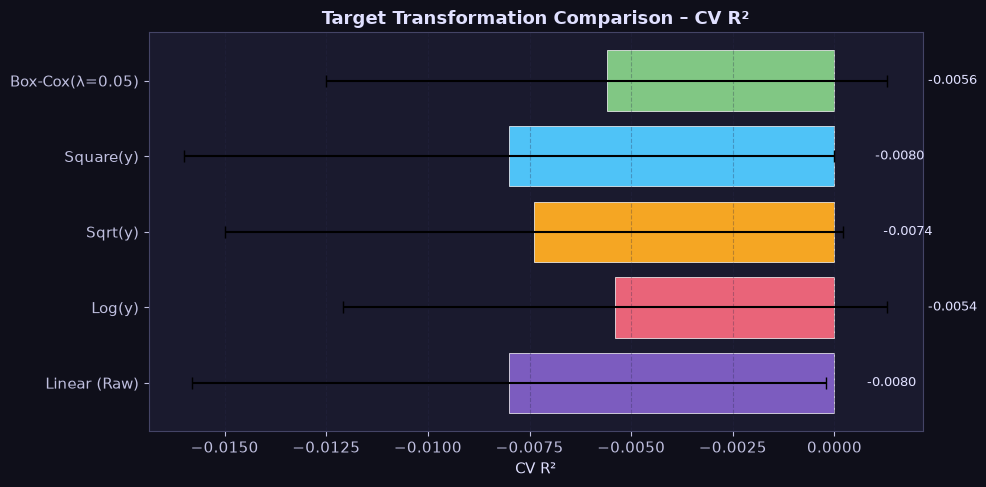

In [25]:
# ── Transformation comparison chart ───────────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor('#0f0f1a')
bar_clrs = [PALETTE[i % len(PALETTE)] for i in range(len(transform_df))]
ax.barh(transform_df['Transform'], transform_df['CV_R2_Mean'],
        xerr=transform_df['CV_R2_Std'], color=bar_clrs,
        edgecolor='white', linewidth=0.5, capsize=4)
for i, (v, s) in enumerate(zip(transform_df['CV_R2_Mean'], transform_df['CV_R2_Std'])):
    ax.text(v + s + 0.001, i, f'{v:.4f}', va='center', fontsize=9, color='#e0e0ff')
ax.set_title('Target Transformation Comparison – CV R²', fontsize=13)
ax.set_xlabel('CV R²'); ax.xaxis.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('../../reports/task_10_transformation_comparison.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

## 6. Product Segmentation by Price Band

In [26]:
# Rank before qcut so tied prices still form four non-empty bands.
price_labels = ['Low', 'Lower-Mid', 'Upper-Mid', 'High']
wdf['Price_Band'] = pd.qcut(
    wdf[FEATURE_COL].rank(method='first'), q=4, labels=price_labels
)
print(wdf['Price_Band'].value_counts().sort_index())
logger.info('Product price bands created.')

2026-11-19 15:23:36,172 | INFO | Product price bands created.


Price_Band
Low          385
Lower-Mid    385
Upper-Mid    384
High         385
Name: count, dtype: int64


In [27]:
# ── Units-sold tiers by percentile ─────────────────────────────────────────────
sales_labels = ['Low', 'Mid', 'High']
wdf['Sales_Tier'] = pd.qcut(
    wdf[TARGET_COL].rank(method='first'), q=3, labels=sales_labels
)
print(wdf['Sales_Tier'].value_counts().sort_index())

Sales_Tier
Low     513
Mid     513
High    513
Name: count, dtype: int64


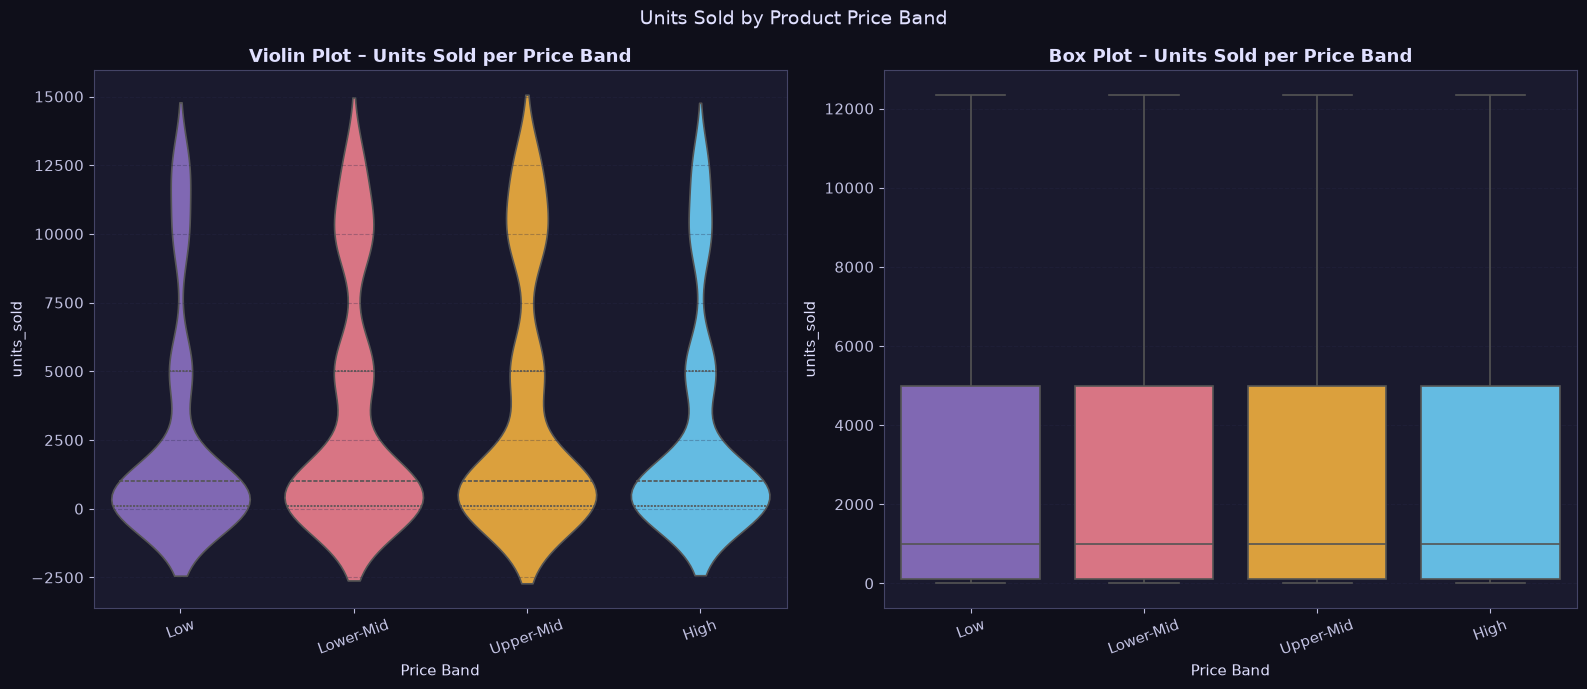

2026-11-19 15:23:38,218 | INFO | Price-band sales plots saved.


In [28]:
# ── Violin + Box plot: Units Sold by Price Band ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Units Sold by Product Price Band', fontsize=14, color='#e0e0ff')

group_palette = dict(zip(price_labels, PALETTE[:len(price_labels)]))

sns.violinplot(data=wdf, x='Price_Band', y=TARGET_COL,
               palette=group_palette, ax=axes[0],
               inner='quartile', linewidth=1.2)
axes[0].set_title('Violin Plot – Units Sold per Price Band')
axes[0].set_xlabel('Price Band'); axes[0].set_ylabel(TARGET_COL)
axes[0].tick_params(axis='x', rotation=20)
axes[0].yaxis.grid(True, alpha=0.3)

sns.boxplot(data=wdf, x='Price_Band', y=TARGET_COL,
            palette=group_palette, ax=axes[1],
            linewidth=1.2, flierprops={'marker': 'o', 'markersize': 3,
                                        'alpha': 0.4, 'color': '#e96479'})
axes[1].set_title('Box Plot – Units Sold per Price Band')
axes[1].set_xlabel('Price Band'); axes[1].set_ylabel(TARGET_COL)
axes[1].tick_params(axis='x', rotation=20)
axes[1].yaxis.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../../reports/task_10_units_sold_by_price_band.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()
logger.info('Price-band sales plots saved.')

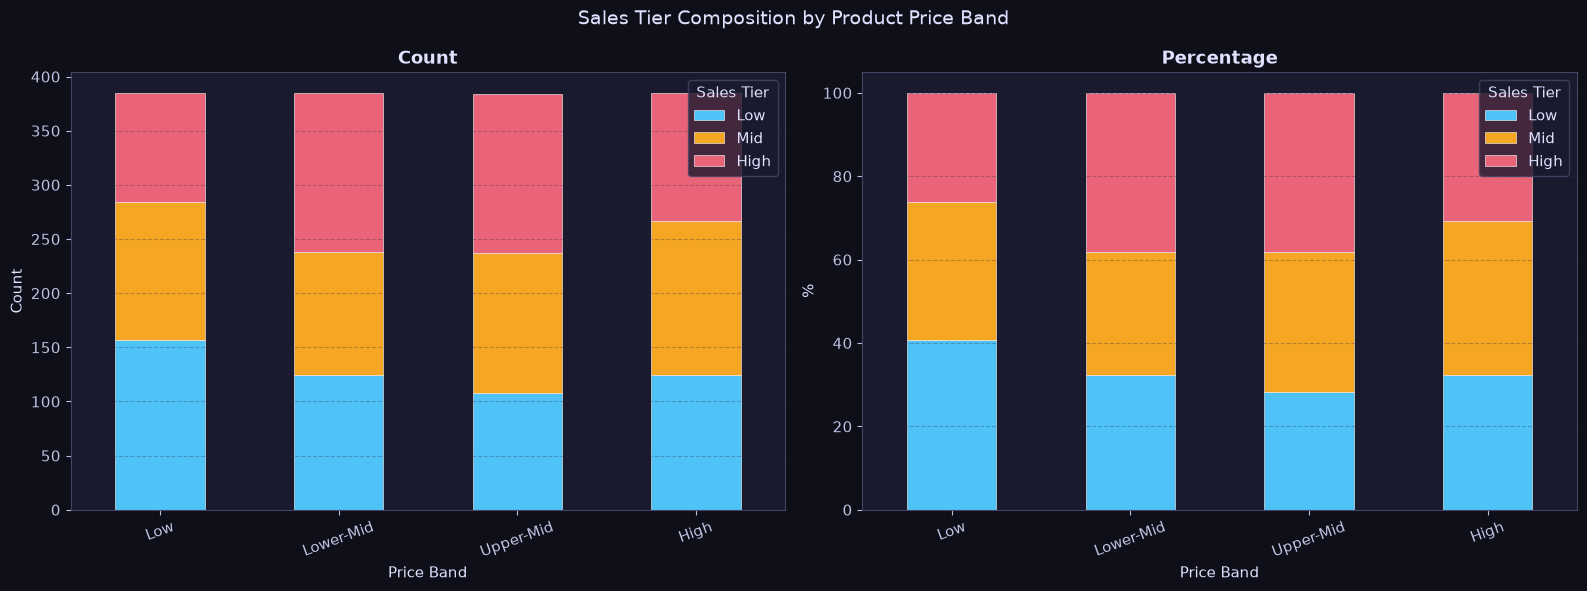

In [29]:
# ── Sales-tier composition by Price Band (stacked bar) ─────────────────────────
tier_pivot = wdf.groupby(['Price_Band', 'Sales_Tier'], observed=False).size().unstack(fill_value=0)
tier_pct   = tier_pivot.div(tier_pivot.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Sales Tier Composition by Product Price Band', fontsize=14, color='#e0e0ff')

tier_pivot.plot(kind='bar', stacked=True, ax=axes[0],
                color=['#4fc3f7', '#f5a623', '#e96479'], edgecolor='white', linewidth=0.4)
axes[0].set_title('Count'); axes[0].set_xlabel('Price Band'); axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=20); axes[0].yaxis.grid(True, alpha=0.3)
axes[0].legend(title='Sales Tier', loc='upper right')

tier_pct.plot(kind='bar', stacked=True, ax=axes[1],
              color=['#4fc3f7', '#f5a623', '#e96479'], edgecolor='white', linewidth=0.4)
axes[1].set_title('Percentage'); axes[1].set_xlabel('Price Band'); axes[1].set_ylabel('%')
axes[1].tick_params(axis='x', rotation=20); axes[1].yaxis.grid(True, alpha=0.3)
axes[1].legend(title='Sales Tier', loc='upper right')

plt.tight_layout()
plt.savefig('../../reports/task_10_sales_tier_by_price_band.png', dpi=150,
            bbox_inches='tight', facecolor='#0f0f1a')
plt.show()

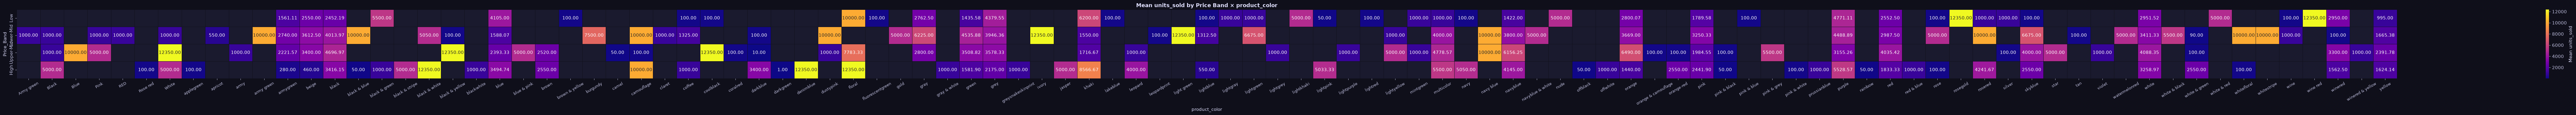

2026-11-19 15:23:50,863 | INFO | Price-band × product-color heatmap saved.


In [30]:
# ── Heatmap: Mean units sold by Price Band × Product Color ─────────────────────
if CATEGORY_COL in wdf.columns:
    heat = wdf.groupby(['Price_Band', CATEGORY_COL], observed=False)[TARGET_COL].mean().unstack()
    if not heat.empty:
        fig, ax = plt.subplots(figsize=(max(8, len(heat.columns)), max(4, len(heat) * 0.8)))
        fig.patch.set_facecolor('#0f0f1a')
        sns.heatmap(heat, annot=True, fmt='.2f', cmap='plasma', ax=ax,
                    linewidths=0.5, linecolor='#0f0f1a',
                    cbar_kws={'label': f'Mean {TARGET_COL}'})
        ax.set_title(f'Mean {TARGET_COL} by Price Band × {CATEGORY_COL}', fontsize=13)
        ax.tick_params(axis='x', rotation=30, labelsize=9)
        plt.tight_layout()
        plt.savefig('../../reports/task_10_price_band_color_heatmap.png', dpi=150,
                    bbox_inches='tight', facecolor='#0f0f1a')
        plt.show()
        logger.info('Price-band × product-color heatmap saved.')
else:
    print('No product category column found – skipping heatmap.')

## 7. Price-Band Profile & Save Reports

In [31]:
price_band_profile = wdf.groupby('Price_Band', observed=False)[TARGET_COL].agg(
    Count='count',
    Mean='mean',
    Median='median',
    Std='std',
    Min='min',
    Max='max',
    P25=lambda x: x.quantile(0.25),
    P75=lambda x: x.quantile(0.75)
).round(4).reset_index()

price_band_profile.to_csv('../../reports/task_10_price_band_profiles.csv', index=False)
summary_df.to_csv('../../reports/task_10_polynomial_regression.csv', index=False)

logger.info('All reports saved.')
print('✅ Task 10 complete.')
display(price_band_profile)
display(summary_df)

2026-11-19 15:23:51,502 | INFO | All reports saved.


✅ Task 10 complete.


,Price_Band,Count,Mean,Median,Std,Min,Max,P25,P75
0,Low,385,2570.1143,1000.0,4010.6243,1,12350,100.0,5000.0
1,Lower-Mid,385,3508.2883,1000.0,4301.8378,6,12350,100.0,5000.0
2,Upper-Mid,384,3688.2969,1000.0,4463.1210,1,12350,100.0,5000.0
3,High,385,2846.2494,1000.0,3982.2062,1,12350,100.0,5000.0


,Degree,CV_R2_Mean,CV_R2_Std,CV_RMSE_Mean,CV_RMSE_Std,Train_R2
0,1,-0.0080,0.0078,4216.5459,186.1789,0.0001
1,2,0.0083,0.0138,4182.4324,187.5138,0.0170
2,3,0.0122,0.0121,4174.4426,192.7706,0.0215
3,4,0.0116,0.0141,4175.7202,192.4084,0.0225
4,5,0.0105,0.0142,4178.1150,193.7057,0.0226
